# INITIAL DATA UNDERSTANDING, EDA, PRE-PROCESSING 
### SALSABILA AURELIA OKTANIOPUTRI TP078641


In [ ]:
pip install pandas numpy matplotlib seaborn scipy openpyxl statsmodels

     ---------------------------------------- 0.0/52.8 kB ? eta -:--:--
     ---------------------------------------- 52.8/52.8 kB 2.8 MB/s eta 0:00:00
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/119.8 kB ? eta -:--:--
     -------------------------------------- 119.8/119.8 kB 7.3 MB/s eta 0:00:00
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/9.9 MB 9.4 MB/s eta 0:00:02
   --- ------------------------------------ 0.9/9.9 MB 9.3 MB/s eta 0:00:01
   ---- ----------------------------------- 1.2/9.9 MB 9.4 MB/s eta 0:00:01
   ------ --------------------------------- 1.5/9.9 MB 8.6 MB/s eta 0:00:01
   -------- ------------------------------- 2.0/9.9 MB 9.


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\asus\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


#### DATA UNDERSTANDING & EXPLORATION
1. Import libraries
2. Load dataset
3. Inspect Data: Missing, values, data types
4. Verify orderdate: make sure its datetime, reset index for chronological order
5. Check unique values
6. Daily aggregation
7. Weekly aggregation
8. Detect missing date gaps
9. EDA

In [1]:
# 1) Import libraries ──────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [ ]:
# 2) Load dataset ──────────────────────────────────────────────────
# store in pandas df
# ""C:\Users\asus\FYP\data\Global skincare and Beauty e-store_E-commerce Analysis_English.xlsx""
#FILE_PATH = r"C:\Users\asus\Downloads\Global skincare and Beauty e-store_E-commerce Analysis_English.xlsx"


FILE_PATH = r"C:\Users\asus\FYP\data\Global skincare and Beauty e-store_E-commerce Analysis_English.xlsx"

df = pd.read_excel(FILE_PATH, sheet_name='data')

print(f"Shape: {df.shape}")
print(f"\nColumns:\n{df.columns.tolist()}")
df.head(3)

Shape: (51290, 19)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Customer ID', 'Segment', 'City', 'State', 'Country', 'Country latitude', 'Country longitude', 'Region', 'Market', 'Subcategory', 'Category', 'Product', 'Quantity', 'Sales', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Customer ID,Segment,City,State,Country,Country latitude,Country longitude,Region,Market,Subcategory,Category,Product,Quantity,Sales,Discount,Profit
0,46682,IZ-2012-LW699061-40911,2020-01-03,LW-699061,Corporate,Mosul,Ninawa,Iraq,33.223191,43.679291,Western Asia,Asia Pacific,"bath oils, bubbles and soaks",Body care,Head & Shoulders Classic Clean Shampoo,20,600,0.0,300.0
1,10124,US-2012-BT1130518-40912,2020-01-04,BT-1130518,Self-Employed,Pilar,Alagoas,Brazil,-14.235004,-51.925280,South America,LATAM,"bath oils, bubbles and soaks",Body care,Kiehl's Ultra Facial Overnight Hydrating Masque,2,40,0.6,-4.0
2,9067,MX-2012-AW1093031-40912,2020-01-04,AW-1093031,Self-Employed,Santiago de Cuba,Santiago de Cuba,Cuba,21.521757,-77.781167,Caribbean,LATAM,"bath oils, bubbles and soaks",Body care,Golden Vine Bracelet,1,151,0.0,75.5


In [3]:
# 3) Basic inspection ──────────────────────────────────────────────
# check: missing values, datatype, duplicate, convert orderdate

# Data types
print("─── Data Types ───")
print(df.dtypes)

# Null values
print("\n─── Null Values ───")
print(df.isnull().sum())

# Duplicates
print(f"\n─── Duplicate Rows: {df.duplicated().sum()} ───")

# Basic stats for numeric columns
print("\n─── Descriptive Statistics ───")
df[['Quantity', 'Sales', 'Discount', 'Profit']].describe().round(2)

─── Data Types ───
Row ID                        int64
Order ID                        str
Order Date           datetime64[us]
Customer ID                     str
Segment                         str
City                            str
State                           str
Country                         str
Country latitude            float64
Country longitude           float64
Region                          str
Market                          str
Subcategory                     str
Category                        str
Product                         str
Quantity                      int64
Sales                         int64
Discount                    float64
Profit                      float64
dtype: object

─── Null Values ───
Row ID               0
Order ID             0
Order Date           0
Customer ID          0
Segment              0
City                 0
State                0
Country              0
Country latitude     0
Country longitude    0
Region               0
Market   

,Quantity,Sales,Discount,Profit
count,51290.00,51290.00,51290.00,51290.00
mean,5.42,127.07,0.14,20.77
std,4.91,236.07,0.21,83.58
min,1.00,2.00,0.00,-1746.00
25%,2.00,25.00,0.00,0.00
50%,4.00,56.00,0.00,7.20
75%,7.00,132.00,0.20,25.00
max,20.00,3940.00,0.85,1820.00


In [4]:
# 4) Verify Order Date & sort ─────────────────────────────────────
# check that orderdate is datetime format
# reset index so that it is in chronological order

# Confirm it is datetime (already converted by openpyxl, but always verify)
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Sort chronologically and reset index
df = df.sort_values('Order Date').reset_index(drop=True)

print(f"Date range: {df['Order Date'].min().date()}  →  {df['Order Date'].max().date()}")
print(f"Total span: {(df['Order Date'].max() - df['Order Date'].min()).days} days")

# Check for any future dates beyond 2023
future = df[df['Order Date'] > pd.Timestamp('2023-12-31')]
print(f"\nFuture dates (invalid): {len(future)}")

Date range: 2020-01-01  →  2023-12-31
Total span: 1460 days

Future dates (invalid): 0


In [5]:
# 5) Unique value counts ───────────────────────────────────────────
# counting unique of categorical columns

categorical_cols = ['Segment', 'Market', 'Region', 'Category', 'Subcategory', 'Country']

for col in categorical_cols:
    print(f"{col} ({df[col].nunique()} unique): {df[col].unique().tolist()[:10]}")
    print()

Segment (3 unique): ['Self-Employed', 'Consumer', 'Corporate']

Market (5 unique): ['Europe', 'Asia Pacific', 'Africa', 'USCA', 'LATAM']

Region (23 unique): ['Northern Europe', 'Oceania', 'Eastern Europe', 'North Africa', 'Canada', 'Western Asia', 'Southeastern Asia', 'Southern Asia', 'Central America', 'Eastern Africa']

Category (5 unique): ['Face care', 'Hair care', 'Body care', 'Make up', 'Home and Accessories']

Subcategory (17 unique): ['face moisturizing products', 'hair colors and toners', 'shampoos and conditioners', 'face masks and exfoliators', 'Body soaps and washes', 'bath oils, bubbles and soaks', 'foundations and concealers', 'body moisturizers', 'Eye shadows and pencils', 'fragrances']

Country (164 unique): ['Sweden', 'Australia', 'Hungary', 'Algeria', 'Canada', 'Iraq', 'United Kingdom', 'Philippines', 'Iran', 'Malaysia']



In [6]:
# 6) Daily aggregation ─────────────────────────────────────────────
# group QUANTITY by DAILY (ORDERDATE) --> this will be used in EDA
# store in df_daily

df_daily = df.groupby('Order Date')['Quantity'].sum().reset_index()
df_daily.columns = ['ds', 'y']
df_daily = df_daily.sort_values('ds').reset_index(drop=True)

print(f"Daily time series shape: {df_daily.shape}")
print(f"\nDaily Quantity stats:")
print(df_daily['y'].describe().round(2))
df_daily.head()

Daily time series shape: (1430, 2)

Daily Quantity stats:
count    1430.00
mean      194.25
std       134.14
min         1.00
25%        92.00
50%       171.50
75%       272.00
max       795.00
Name: y, dtype: float64


,ds,y
0,2020-01-01,17
1,2020-01-02,1
2,2020-01-03,94
3,2020-01-04,85
4,2020-01-05,25


In [7]:
# 7) Weekly aggregation ─────────────────────────────────────────────
# group QUANTITY by WEEKLY (ORDERDATE) --> this will be used in forecasting
# store in df_weekly

df_weekly = df.resample('W', on='Order Date')['Quantity'].sum().reset_index()
df_weekly.columns = ['ds','y']

print(f"Weekly Time Series Shape:  {df_weekly.shape}")
print(f"\nWeekly Quantity Stats: ")
print(df_weekly['y'].describe().round(2))
df_weekly.head()


Weekly Time Series Shape:  (209, 2)

Weekly Quantity Stats: 
count     209.00
mean     1329.08
std       582.46
min       222.00
25%       891.00
50%      1230.00
75%      1701.00
max      3144.00
Name: y, dtype: float64


,ds,y
0,2020-01-05,222
1,2020-01-12,666
2,2020-01-19,448
3,2020-01-26,671
4,2020-02-02,591


In [8]:
# 8) Detect missing dates ──────────────────────────────────────────
# in the daily time series, there is a gap of 31 days usually this happens 0 sales happen on a particular day
# because time series cannot have gap that means we have to fill it in

full_range = pd.date_range(start=df_daily['ds'].min(), end=df_daily['ds'].max(), freq='D')
missing_dates = full_range.difference(df_daily['ds'])

print(f"Total calendar days in range : {len(full_range)}")
print(f"Days with sales data         : {len(df_daily)}")
print(f"Missing dates (no orders)    : {len(missing_dates)}")
print(f"\nMissing dates:\n{missing_dates.tolist()}")

Total calendar days in range : 1461
Days with sales data         : 1430
Missing dates (no orders)    : 31

Missing dates:
[Timestamp('2020-02-20 00:00:00'), Timestamp('2020-03-12 00:00:00'), Timestamp('2020-03-19 00:00:00'), Timestamp('2020-04-09 00:00:00'), Timestamp('2020-04-16 00:00:00'), Timestamp('2020-04-30 00:00:00'), Timestamp('2020-05-28 00:00:00'), Timestamp('2020-07-02 00:00:00'), Timestamp('2020-07-09 00:00:00'), Timestamp('2020-08-13 00:00:00'), Timestamp('2020-08-27 00:00:00'), Timestamp('2020-09-03 00:00:00'), Timestamp('2020-10-22 00:00:00'), Timestamp('2020-12-17 00:00:00'), Timestamp('2020-12-31 00:00:00'), Timestamp('2021-01-14 00:00:00'), Timestamp('2021-02-25 00:00:00'), Timestamp('2021-03-04 00:00:00'), Timestamp('2021-03-18 00:00:00'), Timestamp('2021-03-25 00:00:00'), Timestamp('2021-04-08 00:00:00'), Timestamp('2021-07-22 00:00:00'), Timestamp('2022-02-17 00:00:00'), Timestamp('2022-02-24 00:00:00'), Timestamp('2022-04-21 00:00:00'), Timestamp('2022-04-28 00:00

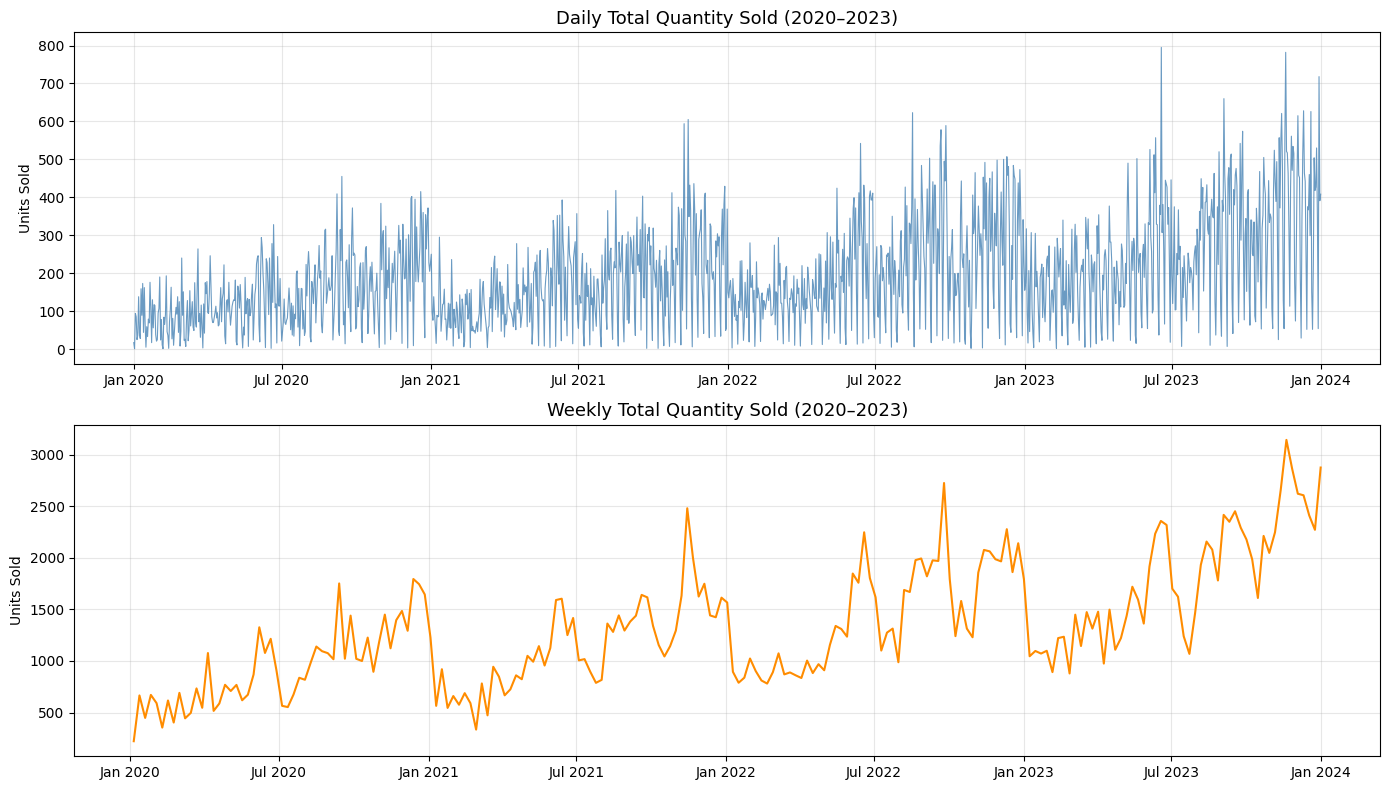

In [9]:
# 9) EDA: Quantity trend over time ──────────────────────────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Daily
axes[0].plot(df_daily['ds'], df_daily['y'], color='steelblue', linewidth=0.8, alpha=0.8)
axes[0].set_title('Daily Total Quantity Sold (2020–2023)', fontsize=13)
axes[0].set_ylabel('Units Sold')
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# Weekly — smoother view for modelling
axes[1].plot(df_weekly['ds'], df_weekly['y'], color='darkorange', linewidth=1.5)
axes[1].set_title('Weekly Total Quantity Sold (2020–2023)', fontsize=13)
axes[1].set_ylabel('Units Sold')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.tight_layout()
plt.show()

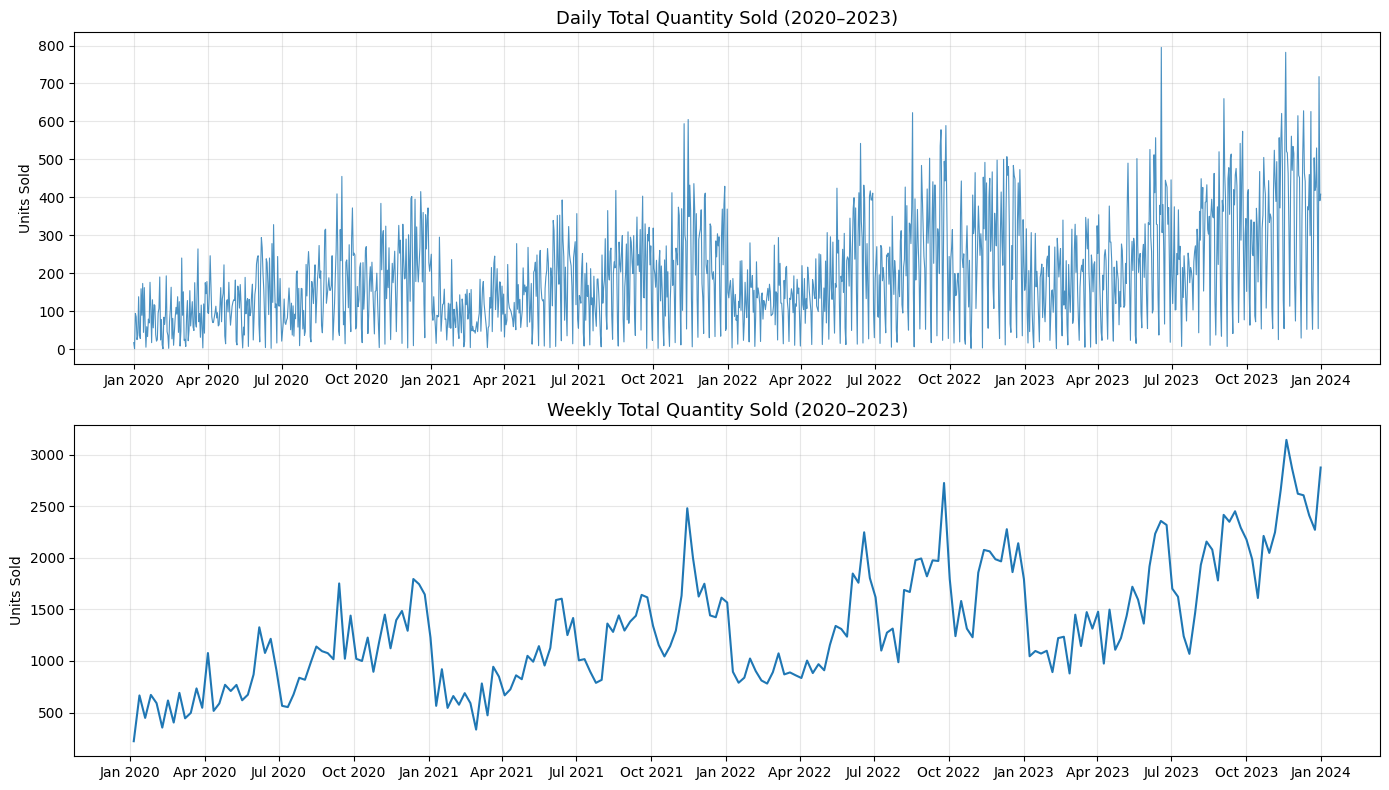

In [10]:
import matplotlib.dates as mdates

# 9) EDA: Quantity trend over time ──────────────────────────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Set quarterly locator
quarter_locator = mdates.MonthLocator(bymonth=[1, 4, 7, 10])
date_format = mdates.DateFormatter('%b %Y')

# Daily
axes[0].plot(df_daily['ds'], df_daily['y'], linewidth=0.8, alpha=0.8)
axes[0].set_title('Daily Total Quantity Sold (2020–2023)', fontsize=13)
axes[0].set_ylabel('Units Sold')
axes[0].xaxis.set_major_locator(quarter_locator)
axes[0].xaxis.set_major_formatter(date_format)

# Weekly — smoother view for modelling
axes[1].plot(df_weekly['ds'], df_weekly['y'], linewidth=1.5)
axes[1].set_title('Weekly Total Quantity Sold (2020–2023)', fontsize=13)
axes[1].set_ylabel('Units Sold')
axes[1].xaxis.set_major_locator(quarter_locator)
axes[1].xaxis.set_major_formatter(date_format)

plt.tight_layout()
plt.show()

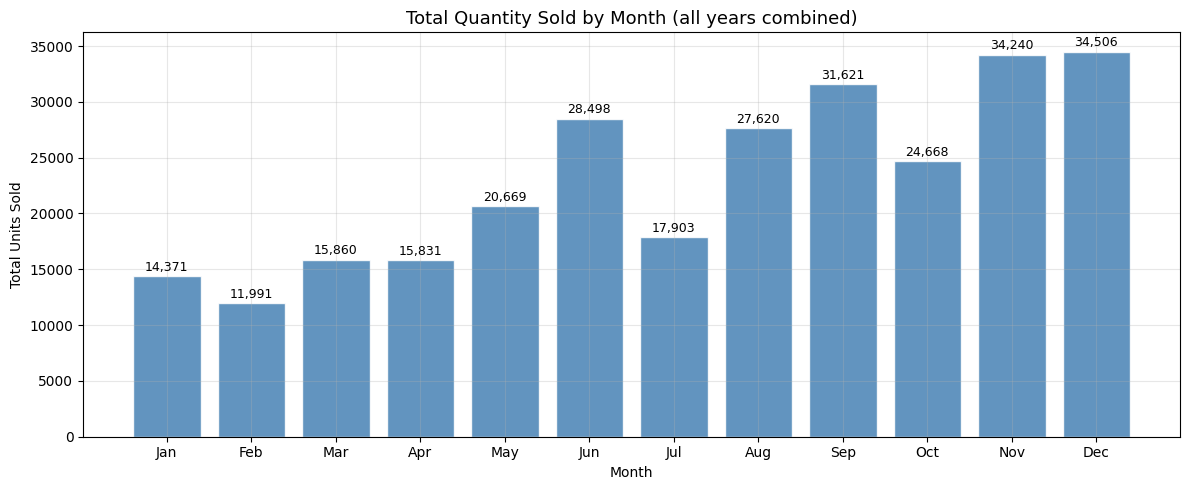

In [11]:
# 10) EDA: Monthly seasonality ──────────────────────────────────────────

df['Month']     = df['Order Date'].dt.month
df['MonthName'] = df['Order Date'].dt.strftime('%b')

month_labels  = ['Jan','Feb','Mar','Apr','May','Jun',
                 'Jul','Aug','Sep','Oct','Nov','Dec']
monthly_total = df.groupby('Month')['Quantity'].sum().reindex(range(1,13))

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(month_labels, monthly_total.values, color='steelblue',
              alpha=0.85, edgecolor='white')
ax.set_title('Total Quantity Sold by Month (all years combined)', fontsize=13)
ax.set_ylabel('Total Units Sold')
ax.set_xlabel('Month')

# Annotate each bar with the value
for bar, val in zip(bars, monthly_total.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{val:,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

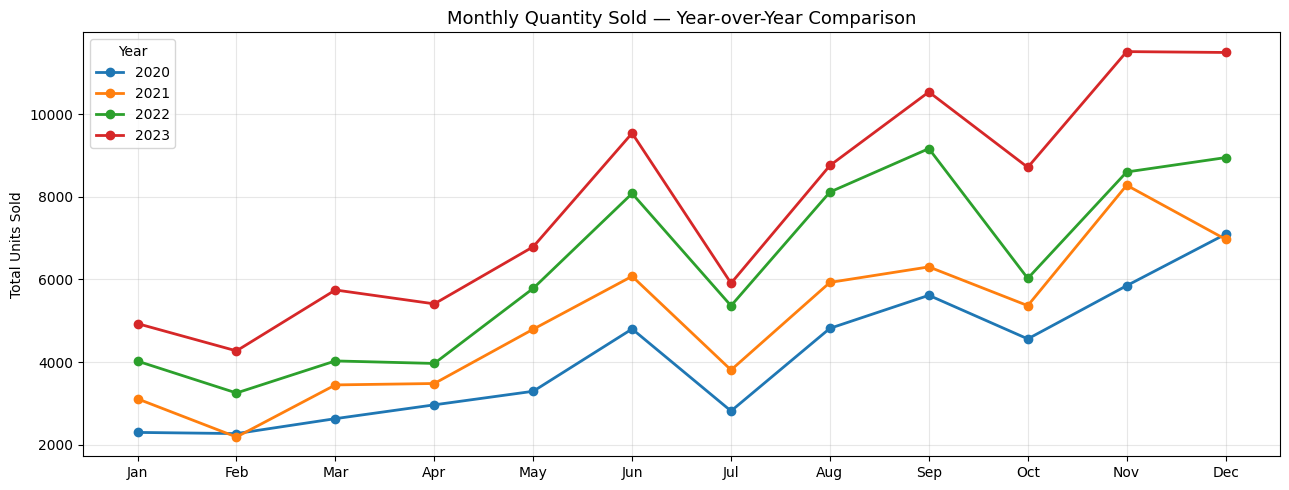


Annual totals:
  2020: 49,039 units
  2021: 59,773 units
  2022: 75,362 units
  2023: 93,604 units


In [12]:
# 11) EDA: Year-over-year comparison ────────────────────────────────────

df['Year'] = df['Order Date'].dt.year

yoy = df.groupby(['Year', 'Month'])['Quantity'].sum().reset_index()
colors = {2020: '#1f77b4', 2021: '#ff7f0e', 2022: '#2ca02c', 2023: '#d62728'}

fig, ax = plt.subplots(figsize=(13, 5))
for year, grp in yoy.groupby('Year'):
    ax.plot(grp['Month'], grp['Quantity'], marker='o', label=str(year),
            color=colors[year], linewidth=2)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title('Monthly Quantity Sold — Year-over-Year Comparison', fontsize=13)
ax.set_ylabel('Total Units Sold')
ax.legend(title='Year')
plt.tight_layout()
plt.show()

# Print YoY growth
yearly_totals = df.groupby('Year')['Quantity'].sum()
print("\nAnnual totals:")
for yr, total in yearly_totals.items():
    print(f"  {yr}: {total:,} units")

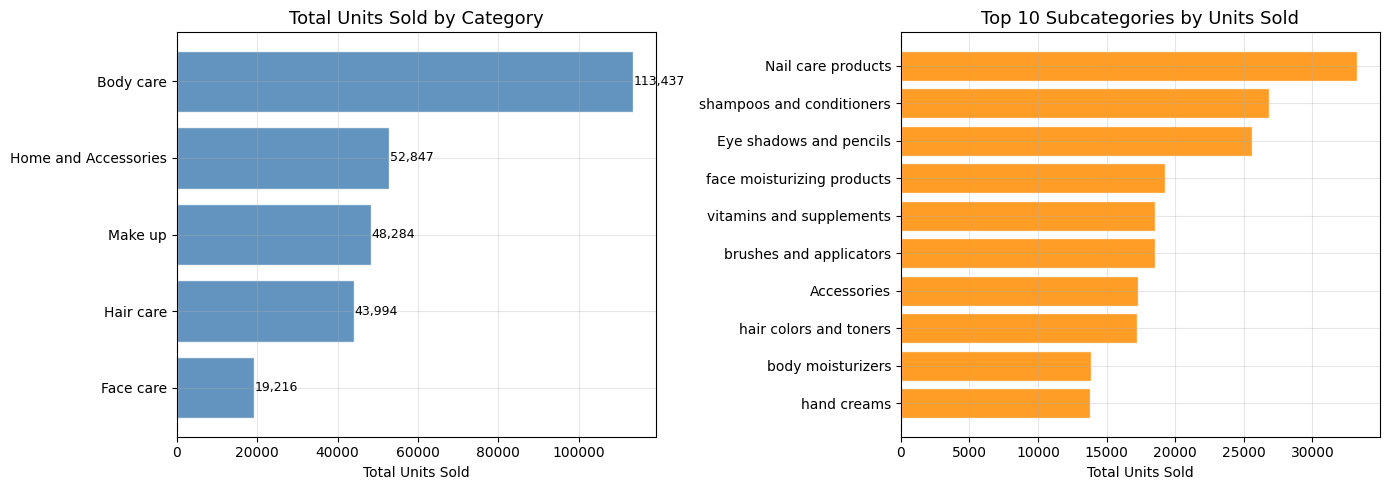

In [13]:
# 12) EDA: Quantity by category and subcategory ─────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Category breakdown
cat_qty = df.groupby('Category')['Quantity'].sum().sort_values(ascending=True)
axes[0].barh(cat_qty.index, cat_qty.values, color='steelblue', alpha=0.85,
             edgecolor='white')
axes[0].set_title('Total Units Sold by Category', fontsize=13)
axes[0].set_xlabel('Total Units Sold')
for i, val in enumerate(cat_qty.values):
    axes[0].text(val + 200, i, f'{val:,}', va='center', fontsize=9)

# Top 10 subcategories
subcat_qty = (df.groupby('Subcategory')['Quantity']
                .sum()
                .sort_values(ascending=False)
                .head(10))
axes[1].barh(subcat_qty.index[::-1], subcat_qty.values[::-1],
             color='darkorange', alpha=0.85, edgecolor='white')
axes[1].set_title('Top 10 Subcategories by Units Sold', fontsize=13)
axes[1].set_xlabel('Total Units Sold')

plt.tight_layout()
plt.show()

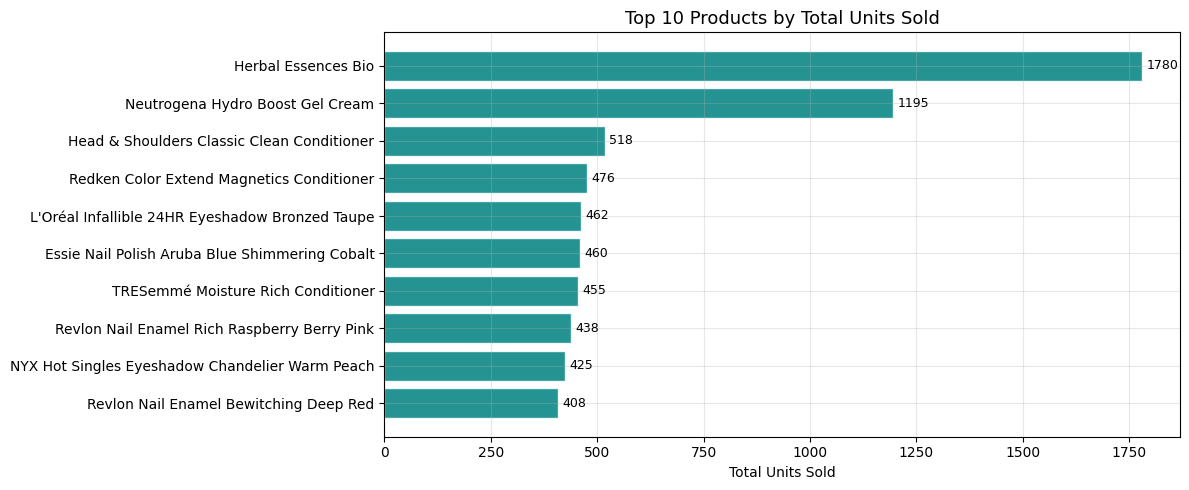

In [14]:
# 13) EDA: Top 10 products by quantity ──────────────────────────────────

top_products = (df.groupby('Product')['Quantity']
                  .sum()
                  .sort_values(ascending=False)
                  .head(10))

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(top_products.index[::-1], top_products.values[::-1],
        color='teal', alpha=0.85, edgecolor='white')
ax.set_title('Top 10 Products by Total Units Sold', fontsize=13)
ax.set_xlabel('Total Units Sold')
for i, val in enumerate(top_products.values[::-1]):
    ax.text(val + 10, i, str(val), va='center', fontsize=9)

plt.tight_layout()
plt.show()

─── Weekly Demand Volatility ───
Mean weekly quantity  : 1,329 units
Std deviation         : 582 units
Coefficient of Variation (CV): 43.8%

Interpretation: MODERATE volatility — some demand variability present.


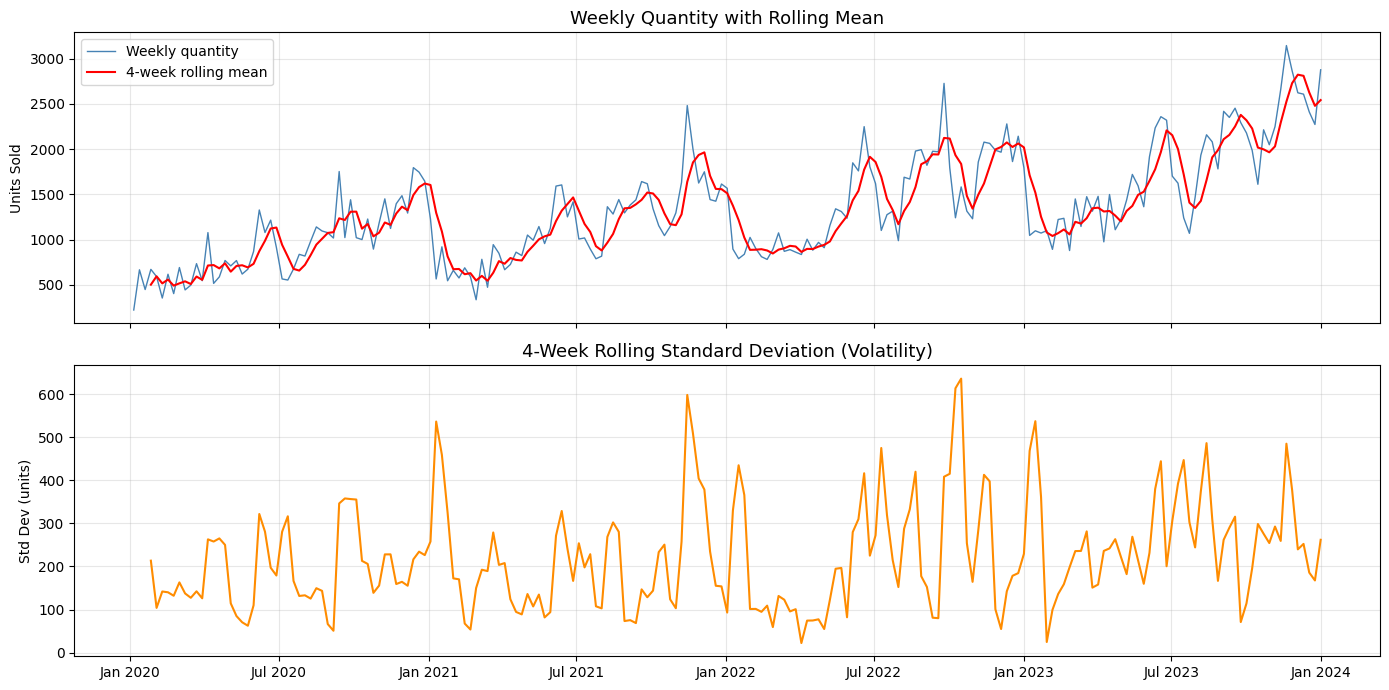

In [15]:
# 14) EDA: Demand volatility ────────────────────────────────────────────

mean_qty = df_weekly['y'].mean()
std_qty  = df_weekly['y'].std()
cv       = (std_qty / mean_qty) * 100

print("─── Weekly Demand Volatility ───")
print(f"Mean weekly quantity  : {mean_qty:,.0f} units")
print(f"Std deviation         : {std_qty:,.0f} units")
print(f"Coefficient of Variation (CV): {cv:.1f}%")
print()
if cv < 30:
    print("Interpretation: LOW volatility — demand is relatively stable.")
elif cv < 60:
    print("Interpretation: MODERATE volatility — some demand variability present.")
else:
    print("Interpretation: HIGH volatility — significant demand uncertainty.")

# Rolling std to show how volatility changes over time
df_weekly_vol = df_weekly.copy()
df_weekly_vol['rolling_mean'] = df_weekly_vol['y'].rolling(4).mean()
df_weekly_vol['rolling_std']  = df_weekly_vol['y'].rolling(4).std()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(df_weekly_vol['ds'], df_weekly_vol['y'],
             color='steelblue', linewidth=1, label='Weekly quantity')
axes[0].plot(df_weekly_vol['ds'], df_weekly_vol['rolling_mean'],
             color='red', linewidth=1.5, label='4-week rolling mean')
axes[0].set_title('Weekly Quantity with Rolling Mean', fontsize=13)
axes[0].set_ylabel('Units Sold')
axes[0].legend()

axes[1].plot(df_weekly_vol['ds'], df_weekly_vol['rolling_std'],
             color='darkorange', linewidth=1.5)
axes[1].set_title('4-Week Rolling Standard Deviation (Volatility)', fontsize=13)
axes[1].set_ylabel('Std Dev (units)')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.tight_layout()
plt.show()

IQR bounds: Lower = -178 units  |  Upper = 542 units
Outlier days detected: 19

Top 19 outlier days (highest demand spikes):
        ds   y
2023-06-18 795
2023-11-18 782
2023-12-29 718
2023-09-03 660
2023-12-10 628
2023-12-19 626
2022-08-16 623
2023-11-13 621
2023-12-03 615
2021-11-13 605
2021-11-08 594
2022-09-26 589
2022-09-20 578
2023-09-26 574
2023-11-25 561
2023-11-17 559
2023-06-11 557
2023-11-10 557
2023-11-12 547


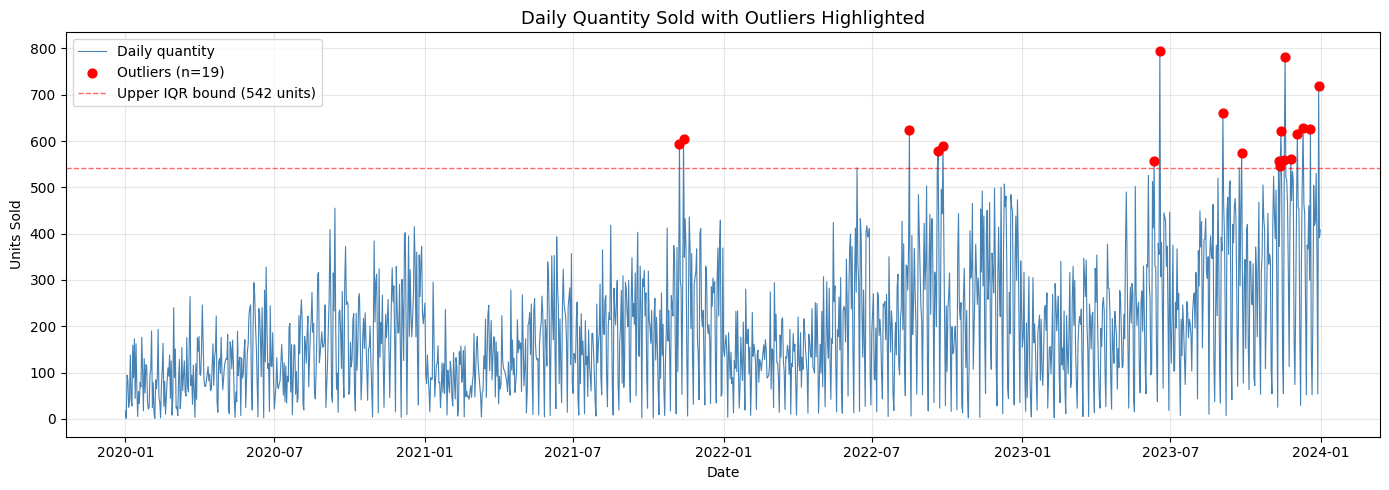


Note: These are genuine demand spikes (e.g. Nov–Dec peak season),
not data errors. We cap rather than remove them in Phase 2.


In [16]:
# 15) EDA: Outlier detection (IQR method on daily series) ───────────────

Q1 = df_daily['y'].quantile(0.25)
Q3 = df_daily['y'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_daily[
    (df_daily['y'] < lower_bound) | (df_daily['y'] > upper_bound)
]

print(f"IQR bounds: Lower = {lower_bound:,.0f} units  |  Upper = {upper_bound:,.0f} units")
print(f"Outlier days detected: {len(outliers)}")
print(f"\nTop 19 outlier days (highest demand spikes):")
print(outliers.sort_values('y', ascending=False).head(19).to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_daily['ds'], df_daily['y'],
        color='steelblue', linewidth=0.8, label='Daily quantity')
ax.scatter(outliers['ds'], outliers['y'],
           color='red', zorder=5, s=40, label=f'Outliers (n={len(outliers)})')
ax.axhline(upper_bound, color='red', linestyle='--',
           linewidth=1, alpha=0.6, label=f'Upper IQR bound ({upper_bound:.0f} units)')
ax.set_title('Daily Quantity Sold with Outliers Highlighted', fontsize=13)
ax.set_ylabel('Units Sold')
ax.set_xlabel('Date')
ax.legend()
plt.tight_layout()
plt.show()

print("\nNote: These are genuine demand spikes (e.g. Nov–Dec peak season),")
print("not data errors. We cap rather than remove them in Phase 2.")

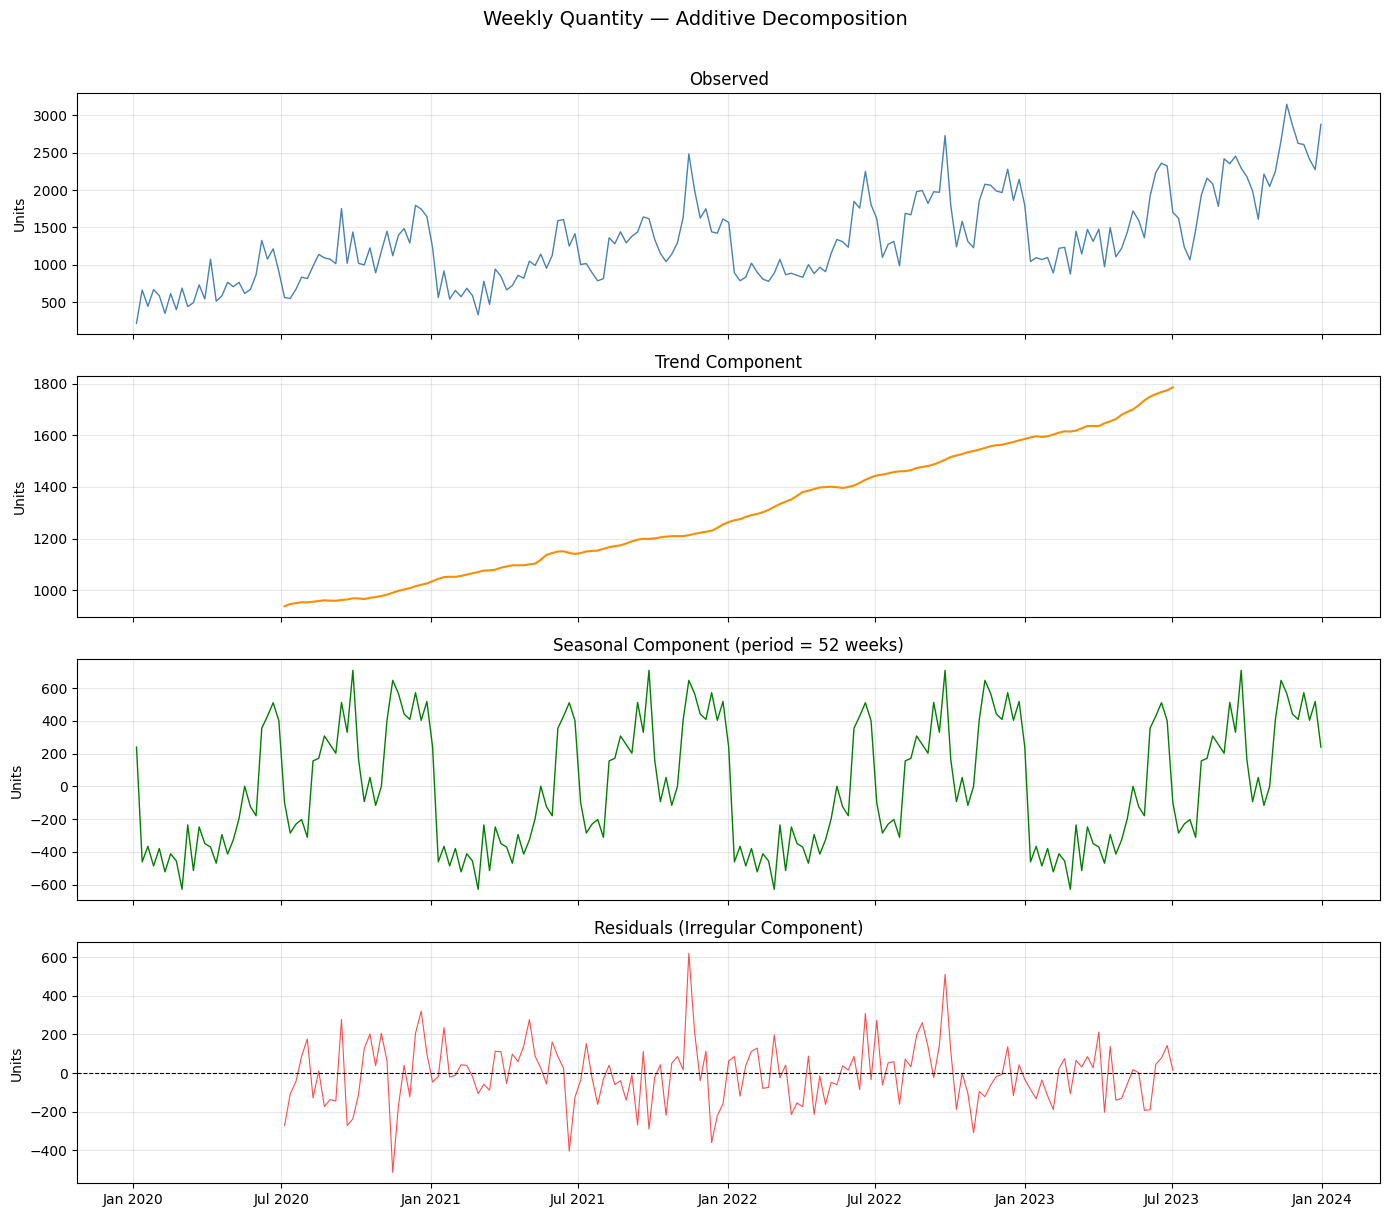

Variance explained by trend    : 17.5%
Variance explained by seasonal : 41.9%
Variance in residuals          : 7.4%


In [17]:
# ── Missing EDA 1: Time series decomposition ──────────────────────────────
from statsmodels.tsa.seasonal import seasonal_decompose

# Use weekly series, period=52 (annual seasonality in weekly data)
decomp = seasonal_decompose(df_weekly['y'], model='additive', period=52)

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

axes[0].plot(df_weekly['ds'], decomp.observed, color='steelblue', linewidth=1)
axes[0].set_title('Observed', fontsize=12)
axes[0].set_ylabel('Units')

axes[1].plot(df_weekly['ds'], decomp.trend, color='darkorange', linewidth=1.5)
axes[1].set_title('Trend Component', fontsize=12)
axes[1].set_ylabel('Units')

axes[2].plot(df_weekly['ds'], decomp.seasonal, color='green', linewidth=1)
axes[2].set_title('Seasonal Component (period = 52 weeks)', fontsize=12)
axes[2].set_ylabel('Units')

axes[3].plot(df_weekly['ds'], decomp.resid, color='red', linewidth=0.8, alpha=0.7)
axes[3].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[3].set_title('Residuals (Irregular Component)', fontsize=12)
axes[3].set_ylabel('Units')
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.suptitle('Weekly Quantity — Additive Decomposition', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Quantify how much variance each component explains
total_var   = np.var(decomp.observed.dropna())
trend_var   = np.var(decomp.trend.dropna())
season_var  = np.var(decomp.seasonal.dropna())
resid_var   = np.var(decomp.resid.dropna())

print(f"Variance explained by trend    : {trend_var/total_var*100:.1f}%")
print(f"Variance explained by seasonal : {season_var/total_var*100:.1f}%")
print(f"Variance in residuals          : {resid_var/total_var*100:.1f}%")

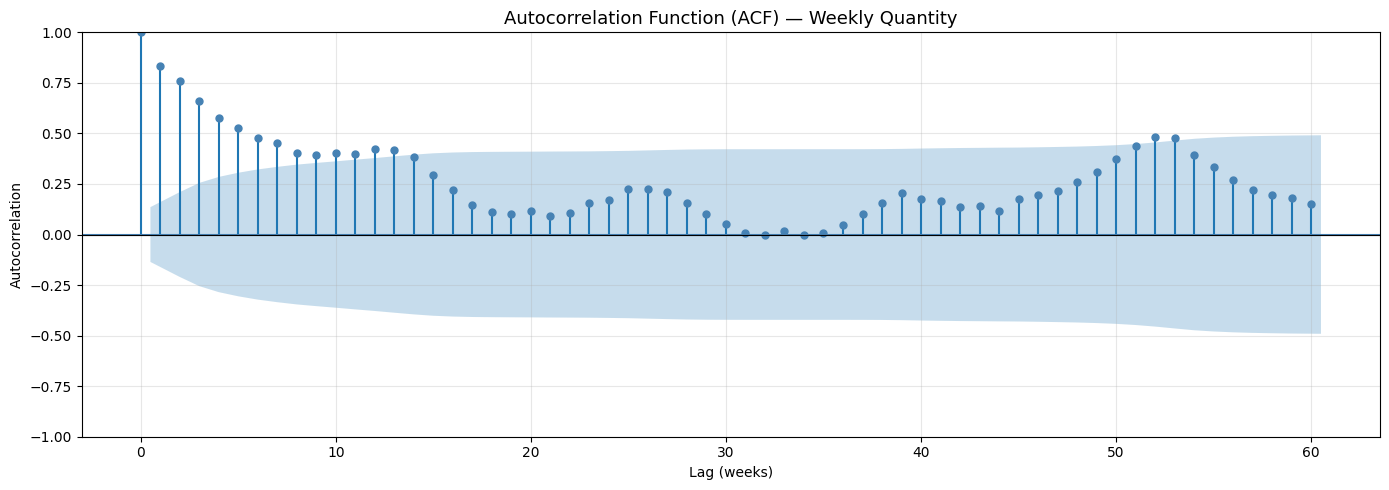

Interpretation guide:
- Bars outside the blue confidence band = statistically significant autocorrelation
- Significant spike at lag 52 = strong annual seasonality
- Slowly decaying bars = non-stationarity (trend present)


In [18]:
# ── Missing EDA 2: Autocorrelation (ACF) ─────────────────────────────────
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(14, 5))
plot_acf(df_weekly['y'], lags=60, ax=ax, color='steelblue', alpha=0.05)
ax.set_title('Autocorrelation Function (ACF) — Weekly Quantity', fontsize=13)
ax.set_xlabel('Lag (weeks)')
ax.set_ylabel('Autocorrelation')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print("Interpretation guide:")
print("- Bars outside the blue confidence band = statistically significant autocorrelation")
print("- Significant spike at lag 52 = strong annual seasonality")
print("- Slowly decaying bars = non-stationarity (trend present)")

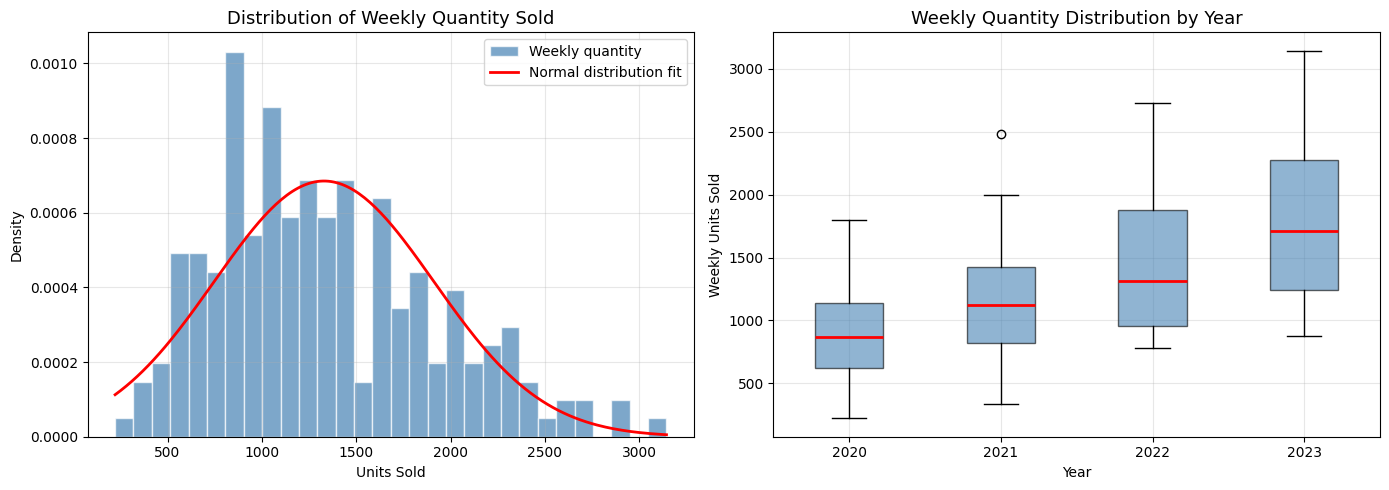

Skewness : 0.631  (0 = perfectly symmetric)
Kurtosis : -0.110  (0 = normal tails, >0 = heavier tails)
Right-skewed distribution: more frequent low-demand weeks,
occasional high-demand spikes — asymmetric demand behavior.
Point forecasts will systematically underestimate peak demand.


In [20]:
# ── Missing EDA 3: Demand distribution ───────────────────────────────────
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with normal curve overlay
axes[0].hist(df_weekly['y'], bins=30, color='steelblue', alpha=0.7,
             edgecolor='white', density=True, label='Weekly quantity')
mu, std = df_weekly['y'].mean(), df_weekly['y'].std()
x = np.linspace(df_weekly['y'].min(), df_weekly['y'].max(), 200)
axes[0].plot(x, stats.norm.pdf(x, mu, std), color='red',
             linewidth=2, label='Normal distribution fit')
axes[0].set_title('Distribution of Weekly Quantity Sold', fontsize=13)
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('Density')
axes[0].legend()

# Boxplot per year
df['Week'] = df['Order Date'].dt.isocalendar().week
weekly_by_year = df.groupby(['Year', df['Order Date'].dt.isocalendar().week
                             .rename('Week')])['Quantity'].sum().reset_index()
yearly_data = [weekly_by_year[weekly_by_year['Year']==yr]['Quantity'].values
               for yr in [2020, 2021, 2022, 2023]]

bp = axes[1].boxplot(yearly_data, labels=['2020','2021','2022','2023'],
                     patch_artist=True,
                     boxprops=dict(facecolor='steelblue', alpha=0.6),
                     medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Weekly Quantity Distribution by Year', fontsize=13)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Weekly Units Sold')

plt.tight_layout()
plt.show()

# Skewness and kurtosis
skewness = df_weekly['y'].skew()
kurt     = df_weekly['y'].kurtosis()
print(f"Skewness : {skewness:.3f}  (0 = perfectly symmetric)")
print(f"Kurtosis : {kurt:.3f}  (0 = normal tails, >0 = heavier tails)")
if skewness > 0.5:
    print("Right-skewed distribution: more frequent low-demand weeks,")
    print("occasional high-demand spikes — asymmetric demand behavior.")
    print("Point forecasts will systematically underestimate peak demand.")

#### DATA PREPROCESSING

In [24]:
# ── Cell 16: Fill missing dates in daily series ───────────────────────────

df_daily_full = df_daily.set_index('ds').reindex(
    pd.date_range(start=df_daily['ds'].min(), end=df_daily['ds'].max(), freq='D')
)
# Note: we do NOT reset_index here — the DatetimeIndex must stay as the index
# so that Cell 17's time-based interpolation works correctly

print(f"Shape before reindex : {df_daily.shape}")
print(f"Shape after reindex  : {df_daily_full.shape}")
print(f"\nMissing values after reindex: {df_daily_full['y'].isnull().sum()}")

Shape before reindex : (1430, 2)
Shape after reindex  : (1461, 1)

Missing values after reindex: 31


In [25]:
# ── Cell 17: Interpolate missing values (time-based) ─────────────────────

# DatetimeIndex is still active here — required for method='time'
df_daily_full['y'] = df_daily_full['y'].interpolate(method='time')

# Now reset the index to bring 'ds' back as a column
df_daily_full = df_daily_full.reset_index().rename(columns={'index': 'ds'})

# Convert to float (required for modelling)
df_daily_full['y'] = df_daily_full['y'].astype(float)

print(f"Missing values after interpolation: {df_daily_full['y'].isnull().sum()}")
print(f"Shape: {df_daily_full.shape}")
print("\nSample of previously missing dates after fill:")
sample_missing = ['2020-02-20', '2020-03-12', '2020-04-09']
print(df_daily_full[df_daily_full['ds'].isin(pd.to_datetime(sample_missing))].to_string(index=False))

Missing values after interpolation: 0
Shape: (1461, 2)

Sample of previously missing dates after fill:
        ds    y
2020-02-20 46.5
2020-03-12 93.0
2020-04-09 83.0


Cap bounds: Lower = $-174  |  Upper = $534
Values capped: 22


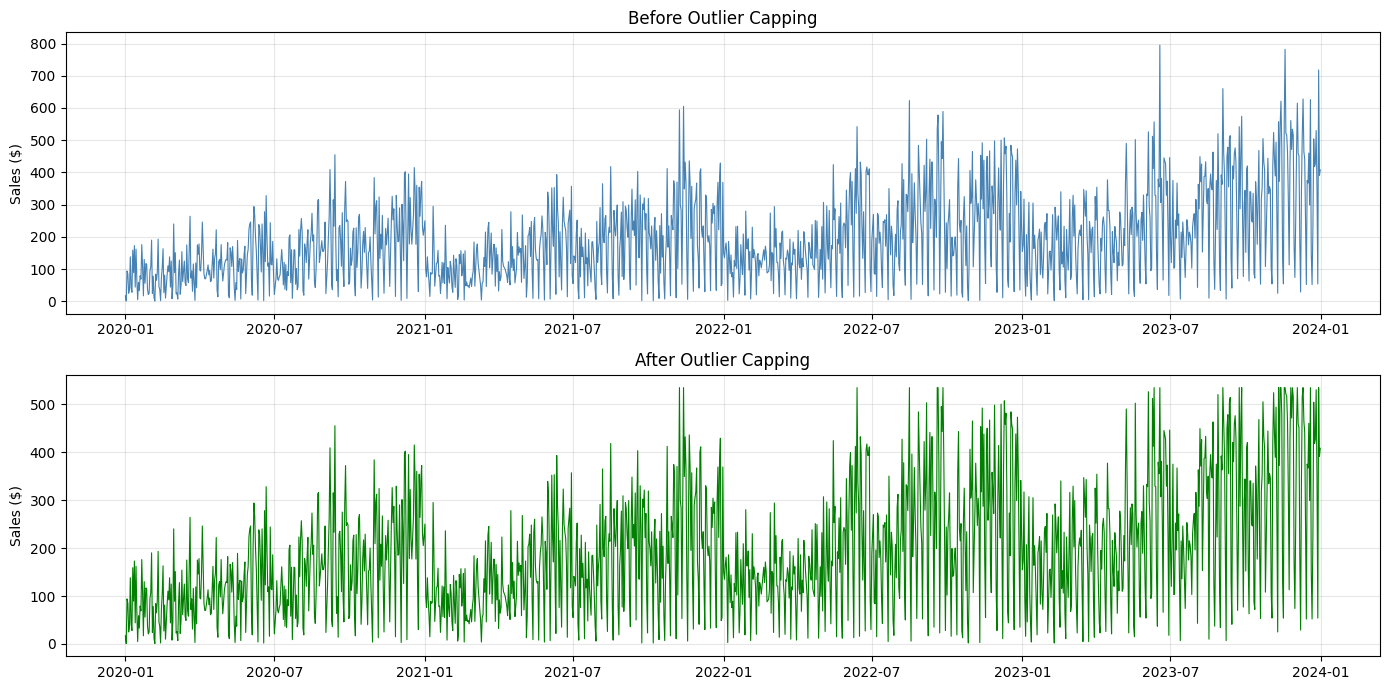

In [26]:
# 18) Cap outliers using IQR (Winsorisation) ───────────────────────
# cap outliers on df_daily full

# Recalculate IQR on the now-complete daily series
# cap outliers on df_daily_full
# save  resulted processed data into df_daily_clean

Q1 = df_daily_full['y'].quantile(0.25)
Q3 = df_daily_full['y'].quantile(0.75)
IQR = Q3 - Q1
lower_cap = Q1 - 1.5 * IQR
upper_cap = Q3 + 1.5 * IQR

df_daily_clean = df_daily_full.copy()
df_daily_clean['y'] = df_daily_clean['y'].clip(lower=lower_cap, upper=upper_cap)

capped_count = ((df_daily_full['y'] > upper_cap) | (df_daily_full['y'] < lower_cap)).sum()
print(f"Cap bounds: Lower = ${lower_cap:,.0f}  |  Upper = ${upper_cap:,.0f}")
print(f"Values capped: {capped_count}")

# Visual comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(df_daily_full['ds'], df_daily_full['y'], color='steelblue', linewidth=0.8)
axes[0].set_title('Before Outlier Capping', fontsize=12)
axes[0].set_ylabel('Sales ($)')

axes[1].plot(df_daily_clean['ds'], df_daily_clean['y'], color='green', linewidth=0.8)
axes[1].set_title('After Outlier Capping', fontsize=12)
axes[1].set_ylabel('Sales ($)')

plt.tight_layout()
plt.show()

In [27]:
# 19) Build final weekly time series ───────────────────────────────

# Re-aggregate from cleaned daily into weekly
df_weekly_clean = df_daily_clean.set_index('ds').resample('W')['y'].sum().reset_index()
df_weekly_clean.columns = ['ds', 'y']
df_weekly_clean['y'] = df_weekly_clean['y'].astype(float)

print(f"Final weekly series shape: {df_weekly_clean.shape}")
print(f"\nFinal weekly sales stats:")
print(df_weekly_clean['y'].describe().round(2))
print(f"\nMissing values: {df_weekly_clean['y'].isnull().sum()}")
df_weekly_clean.head()

Final weekly series shape: (209, 2)

Final weekly sales stats:
count     209.00
mean     1339.33
std       561.53
min       222.00
25%       903.50
50%      1240.00
75%      1701.00
max      2838.50
Name: y, dtype: float64

Missing values: 0


,ds,y
0,2020-01-05,222.0
1,2020-01-12,666.0
2,2020-01-19,448.0
3,2020-01-26,671.0
4,2020-02-02,591.0


so final cleaned weekly --> df_weekly_clean

final cleaned dailyt --> df_daily_clean

Total weeks   : 209
Train         : 146 weeks  (2020-01-05 → 2022-10-16)
Validation    : 21 weeks  (2022-10-23 → 2023-03-12)
Test          : 42 weeks  (2023-03-19 → 2023-12-31)


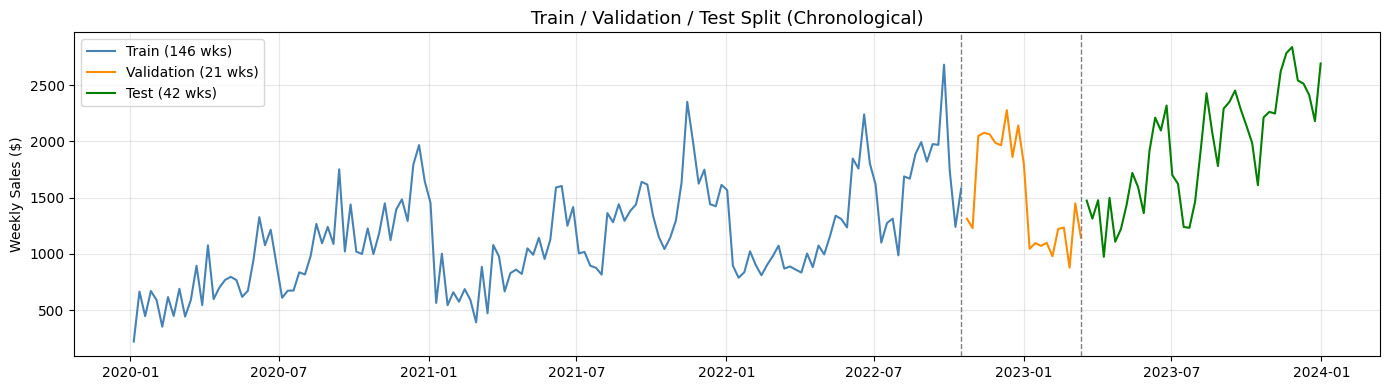

In [28]:
# 20) Split Data: Chronological train / validation / test split ────────────────
# we split only df_weekly_clean because this is what we wanna use to forecast

n = len(df_weekly_clean)
train_end = int(n * 0.70)
val_end   = int(n * 0.80)   # 70% train + 10% validation = 80% cutoff

train = df_weekly_clean.iloc[:train_end].reset_index(drop=True)
val   = df_weekly_clean.iloc[train_end:val_end].reset_index(drop=True)
test  = df_weekly_clean.iloc[val_end:].reset_index(drop=True)

print(f"Total weeks   : {n}")
print(f"Train         : {len(train)} weeks  ({train['ds'].min().date()} → {train['ds'].max().date()})")
print(f"Validation    : {len(val)} weeks  ({val['ds'].min().date()} → {val['ds'].max().date()})")
print(f"Test          : {len(test)} weeks  ({test['ds'].min().date()} → {test['ds'].max().date()})")

# Visual split
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(train['ds'], train['y'], label=f'Train ({len(train)} wks)', color='steelblue')
ax.plot(val['ds'],   val['y'],   label=f'Validation ({len(val)} wks)', color='darkorange')
ax.plot(test['ds'],  test['y'],  label=f'Test ({len(test)} wks)', color='green')
ax.axvline(train['ds'].max(), color='gray', linestyle='--', linewidth=1)
ax.axvline(val['ds'].max(),   color='gray', linestyle='--', linewidth=1)
ax.set_title('Train / Validation / Test Split (Chronological)', fontsize=13)
ax.set_ylabel('Weekly Sales ($)')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 21) Save outputs ─────────────────────────────────────────────────

df_weekly_clean.to_csv('df_weekly_clean.csv', index=False)
train.to_csv('train.csv', index=False)
val.to_csv('val.csv', index=False)
test.to_csv('test.csv', index=False)

print("Saved:")
print("  df_weekly_clean.csv  — full cleaned weekly series (input to both models)")
print("  train.csv            — training set")
print("  val.csv              — validation set")
print("  test.csv             — test set")
print("\nPhase 1 & 2 complete. Ready for Phase 3 model implementation.")